In [1]:
# to highlight specific aspects of the Self-Refine data

In [1]:
import pandas as pd
import numpy as np
import re
import json
from pathlib import Path
from clemcore.clemeval import save_clem_table


root = Path(r"C:\Users\white\Desktop\MSc_thesis\reflexion\selected_episodes")
STATIC = ["bbh", "cladder", "ifeval", "mmlu_pro", "eqbench"]

def subsample_static(root_dir):
    """
    The static benchmark scores need to be analyzed separately from the game scores.
    """
    raw_table = pd.read_csv(Path(root_dir) / "raw.csv", index_col=0)
    is_static = raw_table["game"].isin(STATIC)
    static_rows = raw_table[is_static == True]
    game_rows = raw_table[is_static == False]
    save_clem_table(static_rows, r"C:\Users\white\Desktop\MSc_thesis\reflexion\selected_episodes\static")
    save_clem_table(game_rows, r"C:\Users\white\Desktop\MSc_thesis\reflexion\selected_episodes\games")

subsample_static(root)


 Saved results into C:\Users\white\Desktop\MSc_thesis\reflexion\selected_episodes\static/results.csv and .html

 Saved results into C:\Users\white\Desktop\MSc_thesis\reflexion\selected_episodes\games/results.csv and .html


In [5]:
# read agent traces and highlight the situations where feedback was all 3 "ok"s but the final answer was changed anyway 
# (caution: this step does not evaluate the feedback's correctness)
import json
import glob
import os
STATIC = {"bbh", "cladder", "ifeval", "mmlu_pro", "eqbench"}

runs_paths = [ 
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\Qwen3.5-4B",
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\Qwen3.5-9B",
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\Qwen3.5-27B",
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\Llama-3.1-8B-Instruct"]

fazit = {}
for run in runs_paths:
    
    ok_changed = 0
    ok_unchanged = 0
    not_ok_changed = 0
    not_ok_unchanged = 0
    for path in glob.glob(run + "/**/agent_trace.json", recursive=True):
        game = os.path.relpath(path, run).split(os.sep)[0]
        if game in STATIC:
            continue
        steps = json.load(open(path, encoding = "utf-8"))
        for step in steps:
            changed = False
            feedback = ""
            for entry in step["trace"]:
                if entry["type"] == 'self-feedback':
                    feedback = entry["content"]
                if entry["type"] == 'refined':
                    changed = entry["changed"]

            cut = feedback.find("REASON")
            if cut == -1:
                head = feedback
            else:
                head = feedback[:cut]
            
            all_ok = "problem" not in head.lower()

            if all_ok and changed:
                ok_changed += 1
            elif all_ok:
                ok_unchanged += 1
            elif changed:
                not_ok_changed += 1
            else:
                not_ok_unchanged += 1
    fazit[run] = [{"ok:changed":ok_changed}, {"ok:unchanged":ok_unchanged}, 
                {"not_ok_changed":not_ok_changed}, {"not_ok_unchanged":not_ok_unchanged},
                {"changed": ok_changed + not_ok_changed}, {"unchanged": not_ok_unchanged+ok_unchanged},
                {"changed_rate": (ok_changed + not_ok_changed) / (ok_changed + not_ok_changed + not_ok_unchanged + ok_unchanged)},
                {"ignored_critique": not_ok_unchanged / (not_ok_changed + not_ok_unchanged)},
                {"refined_good_moves":   ok_changed / (ok_changed + ok_unchanged) }
    ]

fazit


{'C:\\Users\\white\\Desktop\\MSc_thesis\\self_refine\\selfrefine-records-full\\playpen-records\\Qwen3.5-4B': [{'ok:changed': 134},
  {'ok:unchanged': 1350},
  {'not_ok_changed': 1355},
  {'not_ok_unchanged': 1023},
  {'changed': 1489},
  {'unchanged': 2373},
  {'changed_rate': 0.3855515277058519},
  {'ignored_critique': 0.4301934398654331},
  {'refined_good_moves': 0.09029649595687332}],
 'C:\\Users\\white\\Desktop\\MSc_thesis\\self_refine\\selfrefine-records-full\\playpen-records\\Qwen3.5-9B': [{'ok:changed': 102},
  {'ok:unchanged': 2238},
  {'not_ok_changed': 1695},
  {'not_ok_unchanged': 516},
  {'changed': 1797},
  {'unchanged': 2754},
  {'changed_rate': 0.3948582729070534},
  {'ignored_critique': 0.23337856173677068},
  {'refined_good_moves': 0.04358974358974359}],
 'C:\\Users\\white\\Desktop\\MSc_thesis\\self_refine\\selfrefine-records-full\\playpen-records\\Qwen3.5-27B': [{'ok:changed': 25},
  {'ok:unchanged': 4266},
  {'not_ok_changed': 2201},
  {'not_ok_unchanged': 222},
  {'

In [ ]:
# now, the per-game rates
import os
runs_paths = [ 
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\Qwen3.5-4B",
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\selfrefine-Qwen3.5-9B",
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\selfrefine-Qwen3.5-27B",
              r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\selfrefine-llama-3.1-8b-instruct"]

fazit = {}
for run in runs_paths:

    per_game = {}
    for path in glob.glob(run + "/**/agent_trace.json", recursive= True):
        rel = os.path.relpath(path, run)
        game = rel.split(os.sep)[0]
        if game not in per_game:
            per_game[game] = [0,0]
        steps = json.load(open(path, encoding = "utf-8"))
        for step in steps:
            for entry in step["trace"]:
                if entry["type"] == 'refined':
                    if entry["changed"] == True:
                        per_game[game][0] += 1
                    else:
                        per_game[game][1] += 1



    fazit[run] = per_game

    for game in per_game:
        per_game[game].append(100 * (per_game[game][0] / (per_game[game][1] + per_game[game][0])))


fazit


{'C:\\Users\\white\\Desktop\\MSc_thesis\\self_refine\\selfrefine-records-full\\playpen-records\\Qwen3.5-4B': {'adventuregame': [306,
   427,
   41.7462482946794],
  'bbh': [94, 10, 90.38461538461539],
  'cladder': [60, 40, 60.0],
  'codenames': [271, 179, 60.22222222222222],
  'dond': [88, 6, 93.61702127659575],
  'eqbench': [57, 43, 56.99999999999999],
  'guesswhat': [77, 277, 21.75141242937853],
  'ifeval': [72, 28, 72.0],
  'imagegame': [38, 23, 62.295081967213115],
  'matchit_ascii': [67, 375, 15.158371040723981],
  'mmlu_pro': [59, 41, 59.0],
  'privateshared': [164, 86, 65.60000000000001],
  'referencegame': [38, 142, 21.11111111111111],
  'taboo': [68, 126, 35.051546391752574],
  'textmapworld': [166, 154, 51.87500000000001],
  'textmapworld_graphreasoning': [165, 93, 63.95348837209303],
  'textmapworld_specificroom': [62, 84, 42.465753424657535],
  'wordle': [44, 71, 38.26086956521739],
  'wordle_noexp': [0, 180, 0.0],
  'wordle_withclue': [40, 3, 93.02325581395348],
  'wordle_

Instance counts --- for reference:

games: 0

images: 0

Llama-3.1-8B-Instruct: 1294

Qwen3.5-27B: 1294

Qwen3.5-4B: 1294

Qwen3.5-9B: 1294

static: 0
Total game episodes:  790
Total static episodes:  504


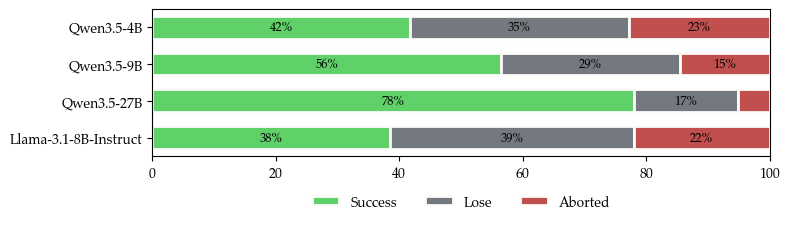

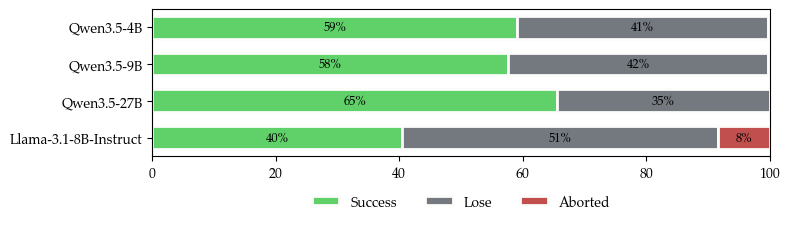

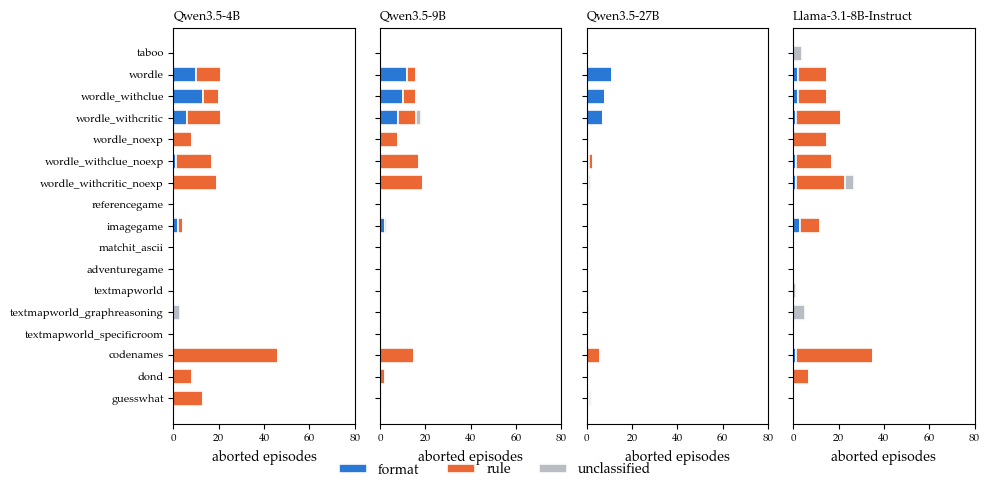

In [2]:
"""
Error analysis for the clembench transcripts.

Input: a root folder path: <root><model><game><experiment><instance.json>
Uses "interactions.json" and "scores.json" for each game instance (= episode)
Output: aborts.csv
        instance_counts.csv

aborts.csv contains names of all episodes which were aborted, and the reasons why,
accompanied by the last 5 events of the episode (events are flattened across
rounds first, because games log the abort reason at different depths: usually it's
the final event, but for adventuregame it's the penultimate, for privateshared 4 
events back).
The reasons for abort were manually collected from the games source code (master.py, 
log_to_self function). 

interactions file structure for every clemgame episode:
{ "meta"  : {...},
  "player_models" : {...},
  "players"       : { ... },
  "turns" : a list of lists
            [ each list is one round, each dict
              inside a list is one event; an event
              always has the following fields: 
                            "from": "..."
                            "to": "...",
                            "timestamp": "...",
                            "action": { "type": "...", "content": "..." }
            ]
}
"""

import pandas as pd
import numpy as np
import re
import json
from pathlib import Path
import csv
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from clemcore.clemeval import save_clem_table


root = Path(r"C:\Users\white\Desktop\MSc_thesis\reflexion\selected_episodes")
instance_counts = {}

#turns = interactions['turns']
#last = turns[-1]                #last round (starting from the GM message to P1)
#print(last[-1])                 #the final event that happened
#print(last[-2])                 #the penultimate event

CAUSES = ["turn_limit_reached", "invalid_format",
      "validation error" , "Invalid instruction format",
      "invalid format", "error",
      "invalid content", "abort game", "aborted",
      "metadata", "turns_limit"]
STATIC = ["bbh", "cladder", "ifeval", "mmlu_pro", "eqbench"]
GENERIC = {"abort game", "game_result = abort", "continue", "end game"}
MODEL_ORDER = ["Qwen3.5-4B", "Qwen3.5-9B", "Qwen3.5-27B", "Llama-3.1-8B-Instruct"]

# === GATHERING GAME OUTCOMES ===

def count_instances(root_dir):
  print("Instance counts --- for reference:")
  for model_dir in root_dir.iterdir():       
    if model_dir.is_dir():       
        #replace with "interactions.json" if needed
        n = len(list(model_dir.rglob("scores.json")))  
        instance_counts[model_dir.name] = n  
        
        print()
        print(model_dir.name + ": " + str(n))


# Uncomment this block to rewrite instance_counts.csv
#   with open(r"C:\Users\white\Desktop\MSc_thesis\baseline_analysis\instance_counts.csv", "w", newline="", encoding="utf-8") as f:
#      w = csv.writer(f)
#      w.writerow(["model", "n_instances"])
#      for model, n in instance_counts.items():
#          w.writerow([model, n])


def collect_aborts(root_dir):
  rows = []       #for the aborts.csv df
  outcomes = []   #for general outcome count

  for scores_file in root_dir.rglob("scores.json"):    
        instance_dir = scores_file.parent              
        interactions_file = instance_dir / "interactions.json"
        scores = json.loads(scores_file.read_text(encoding="utf-8")) 
        model, game, experiment, instance = scores_file.relative_to(root_dir).parts[:4]
        ep = scores['episode scores']
        if ep["Aborted"]:
          outcome = "Aborted"
          interactions= json.loads(interactions_file.read_text(encoding="utf-8"))
          
          turns = interactions["turns"]   #all turns
          flat = []
          for t in turns:
              for e in t:
                  flat.append(e)
          reason = None

          tail = []
          for e in reversed(flat[-5:]):
            a = e["action"]
            tail.append({"from": e["from"], "to": e["to"],
                    "type": a["type"], "content": str(a["content"])[:300]})

          gm_reason = ""
          for e in flat[-5:]:                                  # oldest -> newest
            a = e["action"]
            content = str(a["content"]).strip()
            if not content or content.lower() in GENERIC:
                continue                                      # skip the content-free markers
            if a["type"] == "metadata" and not content.startswith("Error:"):
                continue                                      # skip wordle's turn-stats lines
            if a["type"] in CAUSES:
                gm_reason = content[:300]        

          for e in reversed(flat[-5:]):        # newest event gets written down first
              if e["action"]["type"] in CAUSES:
                  reason = e["action"]
                  detail = reason["content"]

                  rows.append({
                  "model": model,
                  "game": game,
                  "experiment": experiment,
                  "instance": instance,
                  "cause_type": reason["type"],
                  "gm_reason": gm_reason,
                  "detail": str(detail)[:200],
                  "n_rounds": len(turns),
                  "tail": json.dumps(tail, ensure_ascii=False),
                  "group": "static" if game in STATIC else "games"
                  })
                  break
          else:
            rows.append({"model": model, "game": game,
                  "experiment": experiment,
                  "instance": instance, "cause_type": "UNMATCHED",
                    "detail": "", "n_rounds": len(turns), 
                    "group": "static" if game in STATIC else "games",
                    "tail": json.dumps(tail, ensure_ascii=False)})
        elif ep["Success"]:
          outcome = "Success"
        else:
          outcome = "Lose"
        outcomes.append({"model": model, "game": game,      
                           "experiment": experiment,
                           "instance": instance,
                           "group": "static" if game in STATIC else "games",
                           "outcome": outcome})
  return rows, outcomes

# === PLOTTING ===

def plot_outcomes(df, title, out_stem):
        OUTCOME_COLORS = {"Success": "#60d169", "Lose": "#74787f", "Aborted": "#c14f4d"}
        ORDER = ["Success", "Lose", "Aborted"]

        order = [m for m in MODEL_ORDER if m in set(df.model)]
        ct = pd.crosstab(df.model, df.outcome).reindex(index=order[::-1],
                                                         columns=ORDER, fill_value=0)
        pct = ct.div(ct.sum(axis=1), axis=0) * 100

        fig, ax = plt.subplots(figsize=(8, 2.6))
        left = pd.Series(0.0, index=pct.index)
        for oc in ORDER:
            ax.barh(pct.index, pct[oc], left=left, color=OUTCOME_COLORS[oc],
                    label=oc, height=0.62, edgecolor="#fcfcfb", linewidth=2)
            for m in pct.index:                                  
                if pct.loc[m, oc] > 6:
                    ax.text(left[m] + pct.loc[m, oc] / 2, m, f"{pct.loc[m, oc]:.0f}%",
                            ha="center", va="center", color="black", fontsize=9)
            left += pct[oc]

        ax.set_xlim(0, 100)
        ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.45))
        ax.set_title(title, loc="left", pad=12)
        fig.tight_layout()
        fig.savefig(out_stem + ".png", bbox_inches="tight", dpi = 300)
        fig.savefig(out_stem + ".pdf", bbox_inches="tight")

def canonical_reason(s):
    """
    For codenames, which writes an abort reason as dictionary (in all other games, it's a string),
    and wordle, which always puts a prefix "Error:", we need some additional parsing.
    """
    s = str(s).strip()
    if not s or s == "nan":
        return "(not logged)"
    m = re.search(r"'type':\s*'([^']*)'", s)        
    if m:
        return m.group(1)
    if s.startswith("Error:"):                       
        return s[len("Error:"):].strip()
    return s


def plot_causes_by_game_model(df_aborts, df_outcomes, out_path):

        FORMAT = {"The response should contain the 'guess:' keyword exactly once.",
            "The guess should be a single word and should only contain letters.",
            "Invalid grid format","Abort: invalid format in probing.",
            'proposal does not start with "proposal:"',"rambling error",
            "proposal does not include number/name pairs", "clue contains spaces",
            "target appears more than once in utterance","guess appears more than once in utterance"}
        CAT_ORDER  = ["format", "rule", "unclassified"]
        CAT_COLORS = {"format": "#2a78d6", "rule": "#eb6834", "unclassified": "#b9bcc2"}
        GAME_GROUPS = {
      "word games":        ["taboo", "wordle", "wordle_withclue", "wordle_withcritic", "wordle_noexp", "wordle_withclue_noexp", "wordle_withcritic_noexp"],
      "reference":         ["referencegame", "imagegame", "matchit_ascii"],
      "navigation":        ["adventuregame", "textmapworld", "textmapworld_graphreasoning",
                            "textmapworld_specificroom"],
      "dialogue / social": ["codenames", "dond", "guesswhat" ],
  }
        d = df_aborts.copy()

        d["reason"] = [canonical_reason(x) for x in d.gm_reason]
        # this is very hardcoded, but I see no other way to do this because loggers write
        # the reasons why the game aborted a bit differently
        d["category"] = ["format" if r in FORMAT else "unclassified" if r == "(not logged)" else "rule" for r in d["reason"]]

        all_games = sorted(df_outcomes.game.unique())
        pooled = pd.crosstab(d.game, d.category).reindex(all_games, fill_value=0)
        order = [g for grp in GAME_GROUPS.values() for g in grp][::-1]
        models = [m for m in MODEL_ORDER if m in set(d.model)]
        xmax   = pd.crosstab([d.model, d.game], d.category).sum(axis=1).max() * 1.15

        fig, axes = plt.subplots(1, len(models), figsize=(10, 5), sharey=True)
        for ax, m in zip(axes, models):
            ct = (pd.crosstab(d[d.model == m].game, d[d.model == m].category)
                    .reindex(index=order, columns=CAT_ORDER, fill_value=0))
            left = np.zeros(len(ct))
            for c in CAT_ORDER:
                ax.barh(ct.index, ct[c], left=left, color=CAT_COLORS[c], label=c,
                        height=0.7, edgecolor="#fcfcfb", linewidth=1.2)
                left += ct[c].values
            ax.set_xlim(0, 80)
            ax.set_title(m, loc="left", fontsize=9)
            ax.set_xlabel("aborted episodes")
            ax.tick_params(labelsize=8)

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, frameon=False, ncol=3,
                loc="lower center", bbox_to_anchor=(0.5, -0.02))
        fig.suptitle("", x=0.02, ha="left")                              #abort causes by game and model
        fig.tight_layout(); fig.savefig(out_path, bbox_inches="tight")




def main():

    OUT = Path(r"C:\Users\white\Desktop\MSc_thesis\reflexion\selected_episodes")
    IMG = OUT / "images"
    IMG.mkdir(parents=True, exist_ok=True)

    count_instances(root)
    rows, outcomes = collect_aborts(root)

    df = pd.DataFrame(outcomes)
    df_aborts = pd.DataFrame(rows)
    df.to_csv(OUT / "outcomes.csv", index=False, encoding="utf-8")
    df_aborts.to_csv(OUT / "aborts.csv", index=False, encoding="utf-8")

    games_df = df[df.group == "games"]
    static_df = df[df.group == "static"]
    n_games = games_df.groupby("model").size().iloc[0]      # Caution: need to verify if all instance counts per model are equal!
    n_static  = static_df.groupby("model").size().iloc[0]   # (e.g. by rewriting instance_counts.csv)

    print("Total game episodes: ", n_games)
    print("Total static episodes: ", n_static)

    plt.rcParams.update({
      "font.family": "serif",
      "font.serif": ["Palatino Linotype", "Book Antiqua", "DejaVu Serif"],
      "font.size": 10,
      "mathtext.fontset": "custom",          
      "mathtext.rm": "Palatino Linotype",
      "mathtext.it": "Palatino Linotype:italic",
                        })
    plot_outcomes(df[df.group == "games"],
                    "",
                    str(IMG / "figure_general_outcomes"))

    plot_outcomes(df[df.group == "static"],
                    "",
                    str(IMG / "figure_general_outcomes_static"))

    plot_causes_by_game_model(df_aborts[df_aborts.group == "games"],
                                df[df.group == "games"],
                                str(IMG / "fig_causes_by_game_model.pdf"))


        

if __name__ == "__main__":
    main()          

Text(0.02, 0.98, '')

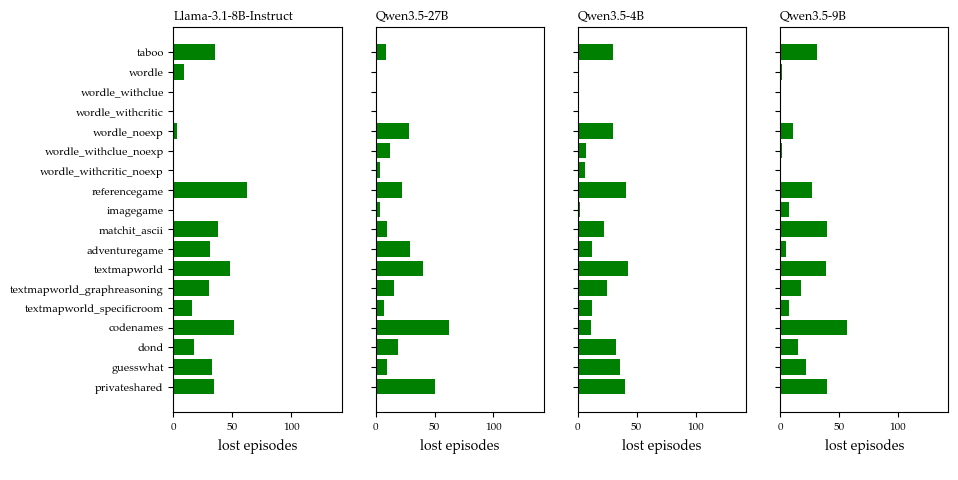

In [ ]:

GAME_GROUPS = {
      "word games":        ["taboo", "wordle", "wordle_withclue", "wordle_withcritic", "wordle_noexp", "wordle_withclue_noexp", "wordle_withcritic_noexp"],
      "reference":         ["referencegame", "imagegame", "matchit_ascii"],
      "navigation":        ["adventuregame", "textmapworld", "textmapworld_graphreasoning",
                            "textmapworld_specificroom"],
      "dialogue / social": ["codenames", "dond", "guesswhat", "privateshared"],
  }
df_outcomes = pd.read_csv(r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\outcomes.csv")
d = df_outcomes.copy()

lost = d[d.outcome == "Lose"]
all_games = sorted(df_outcomes.game.unique())

order = [g for grp in GAME_GROUPS.values() for g in grp][::-1]
models = sorted(d.model.unique())
xmax   = df_outcomes.groupby(["model", "game"]).size().max() * 1.1

fig, axes = plt.subplots(1, len(models), figsize=(10, 5), sharey=True)
for ax, m in zip(axes, models):
        counts = lost[lost.model == m].groupby("game").size().reindex(order, fill_value = 0)
        ax.barh(counts.index, counts.values, color = "green")

        ax.set_xlim(0, xmax)
        ax.set_title(m, loc="left", fontsize=9)
        ax.set_xlabel("lost episodes")
        ax.tick_params(labelsize=8)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=3,
        loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.suptitle("", x=0.02, ha="left")                              #abort causes by game and model
#fig.tight_layout(); fig.savefig(out_path, bbox_inches="tight")


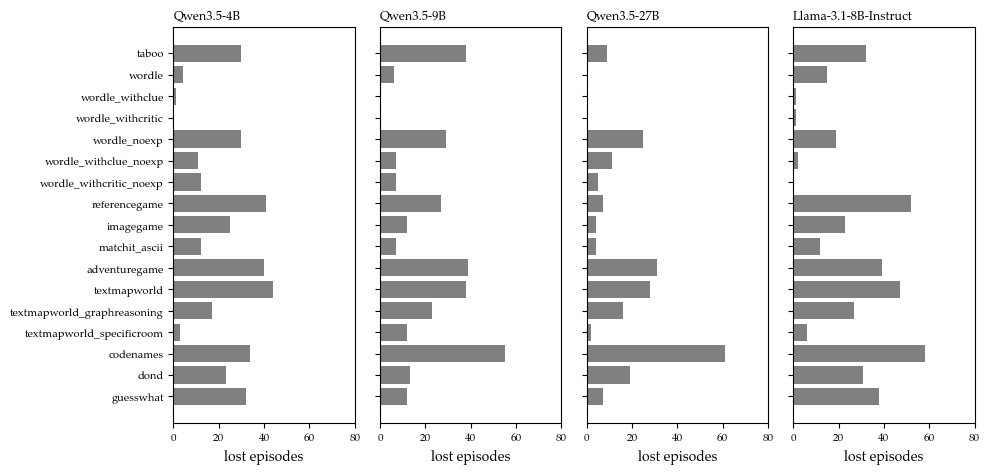

: 

In [ ]:
import pandas as pd

import numpy as np
import re
import json
from pathlib import Path
import csv
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
      "font.family": "serif",
      "font.serif": ["Palatino Linotype", "Book Antiqua", "DejaVu Serif"],
      "font.size": 10,
      "mathtext.fontset": "custom",
      "mathtext.rm": "Palatino Linotype",
      "mathtext.it": "Palatino Linotype:italic",
  })

GAME_GROUPS = {
      "word games":        ["taboo", "wordle", "wordle_withclue", "wordle_withcritic", "wordle_noexp", "wordle_withclue_noexp", "wordle_withcritic_noexp"],
      "reference":         ["referencegame", "imagegame", "matchit_ascii"],
      "navigation":        ["adventuregame", "textmapworld", "textmapworld_graphreasoning",
                            "textmapworld_specificroom"],
      "dialogue / social": ["codenames", "dond", "guesswhat"],
  }

MODEL_ORDER = ["Qwen3.5-4B", "Qwen3.5-9B", "Qwen3.5-27B", "Llama-3.1-8B-Instruct"]

df_outcomes = pd.read_csv(r"C:\Users\white\Desktop\MSc_thesis\baseline_analysis\outcomes.csv")
d = df_outcomes.copy()

lost = d[d.outcome == "Lose"]
all_games = sorted(df_outcomes.game.unique())

order = [g for grp in GAME_GROUPS.values() for g in grp][::-1]
models = [m for m in MODEL_ORDER if m in set(d.model)]
xmax   = df_outcomes.groupby(["model", "game"]).size().max() * 1.1

fig, axes = plt.subplots(1, len(models), figsize=(10, 5), sharey=True)
for ax, m in zip(axes, models):
        counts = lost[lost.model == m].groupby("game").size().reindex(order, fill_value = 0)
        ax.barh(counts.index, counts.values, color = "grey")

        ax.set_xlim(0, 80)
        ax.set_title(m, loc="left", fontsize=9)
        ax.set_xlabel("lost episodes")
        ax.tick_params(labelsize=8)


fig.suptitle("", x=0.02, ha="left")                              #abort causes by game and model
#fig.tight_layout(); fig.savefig(r"C:\Users\white\Desktop\MSc_thesis\baseline_analysis\losses.pdf", bbox_inches="tight")


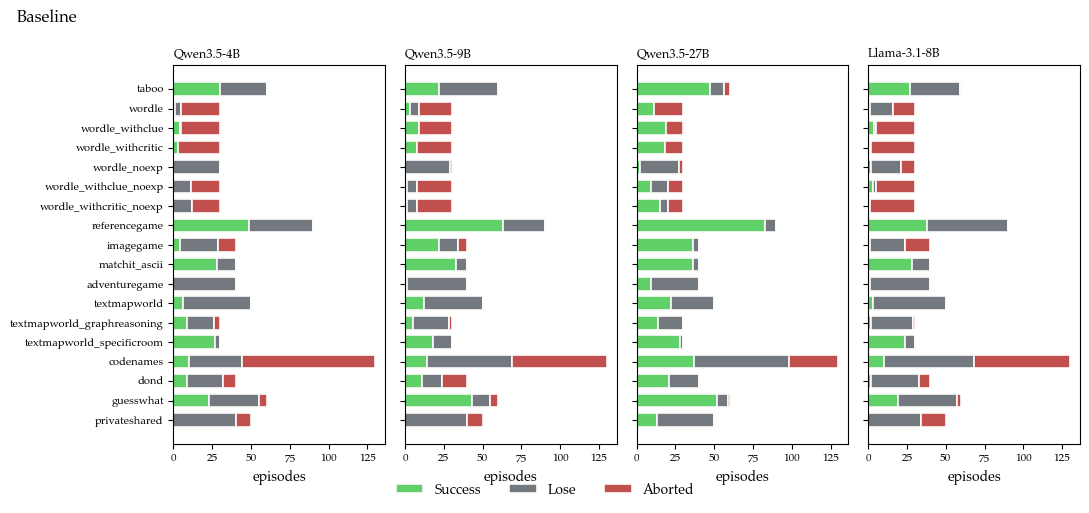

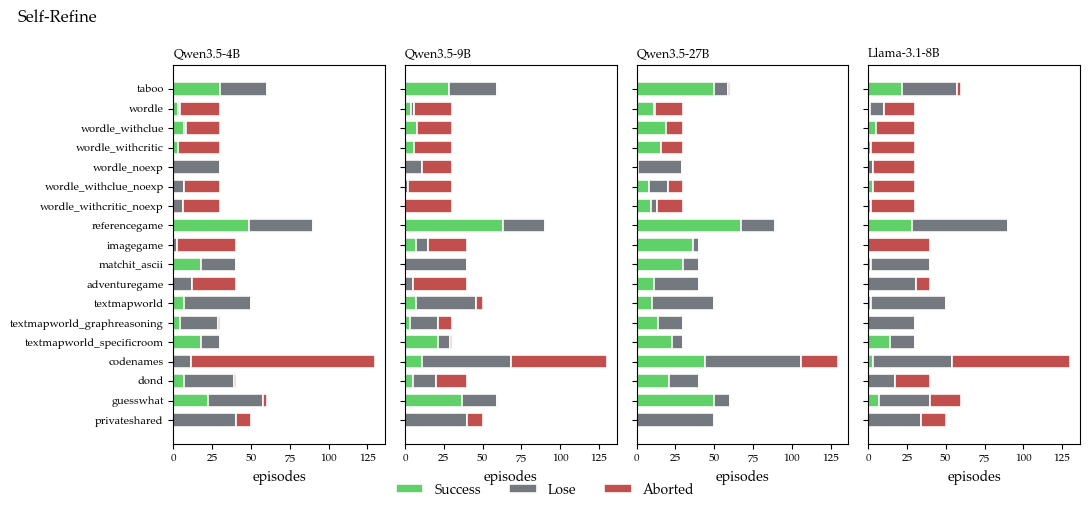

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

GAME_GROUPS = {
    "word games":        ["taboo", "wordle", "wordle_withclue", "wordle_withcritic",
                        "wordle_noexp", "wordle_withclue_noexp", "wordle_withcritic_noexp"],
    "reference":         ["referencegame", "imagegame", "matchit_ascii"],
    "navigation":        ["adventuregame", "textmapworld", "textmapworld_graphreasoning",
                        "textmapworld_specificroom"],
    "dialogue / social": ["codenames", "dond", "guesswhat", "privateshared"],
}

CANON = {"Qwen3.5-4B": "Qwen3.5-4B",  "selfrefine-Qwen3.5-4B": "Qwen3.5-4B",
        "Qwen3.5-9B": "Qwen3.5-9B",  "selfrefine-Qwen3.5-9B": "Qwen3.5-9B",
        "Qwen3.5-27B": "Qwen3.5-27B","selfrefine-Qwen3.5-27B": "Qwen3.5-27B",
        "Llama-3.1-8B-Instruct": "Llama-3.1-8B",
        "llama-3.1-8b-instruct": "Llama-3.1-8B",
        "selfrefine-llama-3.1-8b-instruct": "Llama-3.1-8B"}

MODEL_ORDER = ["Qwen3.5-4B", "Qwen3.5-9B", "Qwen3.5-27B", "Llama-3.1-8B"]


def plot_outcomes_by_game_model(df_outcomes, out_path, title=""):
    ORDER  = ["Success", "Lose", "Aborted"]
    COLORS = {"Success": "#60d169", "Lose": "#74787f", "Aborted": "#c14f4d"}

    d = df_outcomes[df_outcomes.group == "games"].copy()
    d["model"] = d.model.map(CANON)

    order  = [g for grp in GAME_GROUPS.values() for g in grp][::-1]
    models = [m for m in MODEL_ORDER if m in set(d.model)]
    xmax   = pd.crosstab([d.model, d.game], d.outcome).sum(axis=1).max() * 1.05

    fig, axes = plt.subplots(1, len(models), figsize=(11, 5), sharey=True)
    for ax, m in zip(axes, models):
        sub = d[d.model == m]
        ct = (pd.crosstab(sub.game, sub.outcome)
                .reindex(index=order, columns=ORDER, fill_value=0))
        left = np.zeros(len(ct))
        for oc in ORDER:
            ax.barh(ct.index, ct[oc], left=left, color=COLORS[oc], label=oc,
                    height=0.7, edgecolor="#fcfcfb", linewidth=1.2)
            left += ct[oc].values
        ax.set_xlim(0, xmax)
        ax.set_title(m, loc="left", fontsize=9)
        ax.set_xlabel("episodes")
        ax.tick_params(labelsize=8)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, ncol=3,
                loc="lower center", bbox_to_anchor=(0.5, -0.02))
    if title:
        fig.suptitle(title, x=0.02, ha="left")
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")


base = pd.read_csv(r"C:\Users\white\Desktop\MSc_thesis\baseline_analysis\outcomes.csv")
sr   =pd.read_csv(r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\outcomes.csv")

IMG = r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records\images"
plot_outcomes_by_game_model(base, IMG + r"\fig_outcomes_by_game_baseline.pdf", "Baseline")
plot_outcomes_by_game_model(sr,   IMG + r"\fig_outcomes_by_game_selfrefine.pdf", "Self-Refine")

In [ ]:

import os
import re
import glob
import pandas as pd

# ---------------------------------------------------------------- paths
SELFREF       = r"C:\Users\white\Desktop\MSc_thesis\self_refine\selfrefine-records-full\playpen-records"
SR_OUTCOMES   = os.path.join(SELFREF, "outcomes.csv")
BASE_OUTCOMES = r"C:\Users\white\Desktop\MSc_thesis\baseline_analysis\outcomes.csv"
OUT           = r"C:\Users\white\Desktop\MSc_thesis\baseline_analysis"

N_SAMPLE = 25
SEED     = 20261024

STATIC = ["bbh", "cladder", "ifeval", "mmlu_pro", "eqbench"]

GAME_ID = re.compile(r'"game_id"\s*:\s*(\d+)')

# outcomes.csv for the self-refine runs was written BEFORE the folders were
# renamed, so its model column still says "selfrefine-...". Normalise both sides.
CANON = {"Qwen3.5-4B": "Qwen3.5-4B",
        "selfrefine-Qwen3.5-4B": "Qwen3.5-4B",
        "Qwen3.5-9B": "Qwen3.5-9B",
        "selfrefine-Qwen3.5-9B": "Qwen3.5-9B",
        "Qwen3.5-27B": "Qwen3.5-27B",
        "selfrefine-Qwen3.5-27B": "Qwen3.5-27B",
        "Llama-3.1-8B-Instruct": "Llama-3.1-8B",
        "llama-3.1-8b-instruct": "Llama-3.1-8B",
        "selfrefine-llama-3.1-8b-instruct": "Llama-3.1-8B"}

# canonical model name -> folder name on disk, for building paths
FOLDER = {"Qwen3.5-4B": "Qwen3.5-4B",
        "Qwen3.5-9B": "Qwen3.5-9B",
        "Qwen3.5-27B": "Qwen3.5-27B",
        "Llama-3.1-8B": "Llama-3.1-8B-Instruct"}


def game_id_map(root):
    """(model, game, experiment, episode_folder) -> game_id"""
    out = {}
    paths = glob.glob(os.path.join(root, "**", "interactions.json"), recursive=True)
    print("reading %d interaction files" % len(paths))
    for n, path in enumerate(paths, 1):
        if n % 500 == 0:
            print("  %d / %d" % (n, len(paths)), flush=True)
        with open(path, encoding="utf-8") as f:
            head = f.read(600)          # meta sits at the top; don't parse the file
        m = GAME_ID.search(head)
        if m:
            parts = os.path.relpath(path, root).split(os.sep)
            model = CANON.get(parts[0], parts[0])
            out[(model, parts[1], parts[2], parts[3])] = int(m.group(1))
    return out


def main():
    sr = pd.read_csv(SR_OUTCOMES)
    sr["model"] = sr.model.map(lambda x: CANON.get(x, x))

    ids = game_id_map(SELFREF)
    sr["game_id"] = [ids.get((m, g, e, i))
                    for m, g, e, i in zip(sr.model, sr.game, sr.experiment, sr.instance)]

    base = pd.read_csv(BASE_OUTCOMES)
    base["model"] = base.model.map(lambda x: CANON.get(x, x))
    base["game_id"] = [int(i.split("_")[-1]) for i in base.instance]  # instance_00002 -> 2

    print("unmatched game_ids in self-refine:", int(sr.game_id.isna().sum()))

    key = ["model", "game", "experiment", "game_id"]
    paired = base[key + ["outcome", "instance"]].merge(
            sr[key + ["outcome", "instance"]], on=key, suffixes=("_base", "_sr"))
    print("paired:", len(paired), "(expect 5376)")

    flipped = paired[(paired.outcome_base == "Success") & (paired.outcome_sr = "Abort")]
    flipped = flipped[~flipped.game.isin(STATIC)]          # dialogue games only

    print()
    print("flipped Success -> failure (dialogue games):", len(flipped))
    print(flipped.groupby(["model", "outcome_sr"]).size().to_string())
    print()
    print(flipped.groupby("game").size().sort_values(ascending=False).to_string())

    flipped.to_csv(os.path.join(OUT, "flipped_episodes.csv"),
                    index=False, encoding="utf-8")

    sample = flipped.sample(n=N_SAMPLE, random_state=SEED)
    sample = sample.sort_values(["model", "game"])
    sample["dir_sr"] = [os.path.join(SELFREF, FOLDER.get(m, m), g, e, i)
                        for m, g, e, i in zip(sample.model, sample.game,
                                            sample.experiment, sample.instance_sr)]
    sample.to_csv(os.path.join(OUT, "flipped_sample%d_games.csv" % N_SAMPLE),
                index=False, encoding="utf-8")

    print()
    print("--- sample of %d (seed %d) ---" % (N_SAMPLE, SEED))
    for i, (_, r) in enumerate(sample.iterrows(), 1):
        print("%2d. %-13s %-28s %-22s id=%-3d %s"
            % (i, r.model, r.game, r.experiment[:22], r.game_id, r.outcome_sr))
        print("      %s" % r.dir_sr)
    print()
    print(sample.groupby("outcome_sr").size().to_string())


if __name__ == "__main__":
    main()

reading 5376 interaction files
  500 / 5376
  1000 / 5376
  1500 / 5376
  2000 / 5376
  2500 / 5376
  3000 / 5376
  3500 / 5376
  4000 / 5376
  4500 / 5376
  5000 / 5376
unmatched game_ids in self-refine: 0
paired: 5376 (expect 5376)

flipped Success -> failure (dialogue games): 417
model         outcome_sr
Llama-3.1-8B  Aborted       22
              Lose          87
Qwen3.5-27B   Aborted       23
              Lose          95
Qwen3.5-4B    Aborted       17
              Lose          60
Qwen3.5-9B    Aborted       37
              Lose          76

game
matchit_ascii                  81
referencegame                  57
codenames                      39
guesswhat                      35
textmapworld                   28
taboo                          26
textmapworld_specificroom      26
imagegame                      20
dond                           20
textmapworld_graphreasoning    18
privateshared                  13
wordle_withclue                12
wordle_withcritic_noexp      